## Libraries

In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.losses import BinaryFocalCrossentropy
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf
import os

### Load and Prepare Label data

In [59]:
# Set random seed for reproducibility
np.random.seed(42)

benign_dir = r'dataset\data\benign'
malignant_dir = r'dataset\data\malignant'

In [60]:
# Create lists for image paths and labels
image_paths = []
labels = []

for folder, label in [(benign_dir, 'benign'), (malignant_dir, 'malignant')]:
    for img in os.listdir(folder):
        image_paths.append(os.path.join(folder, img))
        labels.append(label)

# Create DataFrame
df = pd.DataFrame({'image_path': image_paths, 'label': labels})

### Split Dataset

In [61]:
# Split into train and test (80-20)
train_full_df, test_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)


### Data Generators with Augmentation

In [75]:
#Enhanced data augmentation for training
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.3,
    height_shift_range=0.3,
    shear_range=0.3,
    zoom_range=0.3,
    horizontal_flip=True,
    vertical_flip=True,
    fill_mode='nearest'
)

val_datagen = ImageDataGenerator(rescale=1./255)
test_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=64,  # Increased batch size for stability
    class_mode='binary'
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=64,
    class_mode='binary'
)

test_generator = test_datagen.flow_from_dataframe(
    test_df,
    x_col='image_path',
    y_col='label',
    target_size=(224, 224),
    batch_size=64,
    class_mode='binary',
    shuffle=False
)

Found 6699 validated image filenames belonging to 2 classes.
Found 1675 validated image filenames belonging to 2 classes.
Found 2094 validated image filenames belonging to 2 classes.


### Build MobileNetV2

In [76]:
# Load pre-trained MobileNetV2 model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(224, 224, 3))

# Add custom layers for binary classification
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)

# Create the final model
model = Model(inputs=base_model.input, outputs=predictions)

# Freeze the base model layers initially
for layer in base_model.layers:
    layer.trainable = False

# Use Binary Focal Loss to focus on hard-to-classify examples (malignant class)
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss=BinaryFocalCrossentropy(gamma=2.0, from_logits=False),
    metrics=['accuracy']
)


### Compute class weights

In [77]:

# Calculate class weights to handle imbalance
num_benign = len(train_df[train_df['label'] == 'benign'])
num_malignant = len(train_df[train_df['label'] == 'malignant'])
total = num_benign + num_malignant
weight_for_benign = total / (2 * num_benign)
weight_for_malignant = total / (2 * num_malignant)
class_weight = {0: weight_for_benign, 1: weight_for_malignant}


### Train Model

In [78]:
#Callbacks for training
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.00001)
early_stopping = EarlyStopping(monitor='val_accuracy', patience=5, restore_best_weights=True)

# Train the model with frozen layers for 10 epochs
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    class_weight=class_weight,
    callbacks=[reduce_lr, early_stopping]
)


C:\Users\Babar Rahim\anaconda3\Lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 270s 3s/step - accuracy: 0.6281 - loss: 0.4603 - val_accuracy: 0.7707 - val_loss: 0.1222 - learning_rate: 0.0010
Epoch 2/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.7275 - loss: 0.1372 - val_accuracy: 0.7242 - val_loss: 0.1343 - learning_rate: 0.0010
Epoch 3/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.7498 - loss: 0.1253 - val_accuracy: 0.7672 - val_loss: 0.1175 - learning_rate: 0.0010
Epoch 4/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 221s 2s/step - accuracy: 0.7573 - loss: 0.1248 - val_accuracy: 0.7910 - val_loss: 0.1130 - learning_rate: 0.0010
Epoch 5/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 222s 2s/step - accuracy: 0.7753 - loss: 0.1213 - val_accuracy: 0.7642 - val_loss: 0.1168 - learning_rate: 0.0010
Epoch 6/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 223s 2s/step - accuracy: 0.7636 - loss: 0.1201 - val_accuracy: 0.7558 - val_loss: 0.1196 - learning_rate: 0.0010
Epoch 7/10
105/105 ━━━━━━━━━━━━━━━━━━━━ 223s 2s/step - accuracy: 0.7701 - loss: 0.

In [81]:
# Continue training for 5 more epochs (total epochs = 15)
history_continued = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=15,  # Total epochs (10 + 5)
    initial_epoch=10,  # Start from epoch 10 (0-based index)
    class_weight=class_weight,
    callbacks=[reduce_lr, early_stopping]  # Same callback instances
)

Epoch 11/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 274s 3s/step - accuracy: 0.8092 - loss: 0.0971 - val_accuracy: 0.8030 - val_loss: 0.1737 - learning_rate: 1.0000e-04
Epoch 12/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 271s 3s/step - accuracy: 0.8048 - loss: 0.1007 - val_accuracy: 0.8078 - val_loss: 0.1895 - learning_rate: 1.0000e-04
Epoch 13/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 322s 3s/step - accuracy: 0.8205 - loss: 0.0932 - val_accuracy: 0.8137 - val_loss: 0.2246 - learning_rate: 1.0000e-04
Epoch 14/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 270s 3s/step - accuracy: 0.8244 - loss: 0.0916 - val_accuracy: 0.8149 - val_loss: 0.2019 - learning_rate: 1.0000e-04
Epoch 15/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 271s 3s/step - accuracy: 0.8257 - loss: 0.0914 - val_accuracy: 0.8263 - val_loss: 0.1825 - learning_rate: 2.0000e-05


In [82]:
# Continue training for 5 more epochs (total epochs = 20)
history_continued = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,  # Total epochs (10 + 15)
    initial_epoch=15,  # Start from epoch 15 (0-based index)
    class_weight=class_weight,
    callbacks=[reduce_lr, early_stopping]  # Same callback instances
)

Epoch 16/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 278s 3s/step - accuracy: 0.8434 - loss: 0.0819 - val_accuracy: 0.8215 - val_loss: 0.1688 - learning_rate: 2.0000e-05
Epoch 17/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 275s 3s/step - accuracy: 0.8360 - loss: 0.0820 - val_accuracy: 0.8269 - val_loss: 0.1584 - learning_rate: 2.0000e-05
Epoch 18/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 274s 3s/step - accuracy: 0.8402 - loss: 0.0800 - val_accuracy: 0.8287 - val_loss: 0.1474 - learning_rate: 2.0000e-05
Epoch 19/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 273s 3s/step - accuracy: 0.8420 - loss: 0.0832 - val_accuracy: 0.8322 - val_loss: 0.1330 - learning_rate: 2.0000e-05
Epoch 20/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 273s 3s/step - accuracy: 0.8493 - loss: 0.0819 - val_accuracy: 0.8322 - val_loss: 0.1279 - learning_rate: 2.0000e-05


### Fine Tunning

In [83]:
#Unfreeze the last 20 layers for fine-tuning
for layer in base_model.layers[-20:]:
    layer.trainable = True

# Recompile the model with a lower learning rate for fine-tuning
model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss=BinaryFocalCrossentropy(gamma=2.0, from_logits=False),
    metrics=['accuracy']
)

# Fine-tune the model for another 20 epochs
history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    class_weight=class_weight,
    callbacks=[reduce_lr, early_stopping]
)


Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 265s 2s/step - accuracy: 0.8348 - loss: 0.0881 - val_accuracy: 0.8090 - val_loss: 0.2266 - learning_rate: 1.0000e-04
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 253s 2s/step - accuracy: 0.8331 - loss: 0.0847 - val_accuracy: 0.8209 - val_loss: 0.2037 - learning_rate: 1.0000e-04
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 245s 2s/step - accuracy: 0.8375 - loss: 0.0825 - val_accuracy: 0.8269 - val_loss: 0.1418 - learning_rate: 1.0000e-04
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 251s 2s/step - accuracy: 0.8313 - loss: 0.0845 - val_accuracy: 0.8293 - val_loss: 0.1461 - learning_rate: 1.0000e-04
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.8458 - loss: 0.0824 - val_accuracy: 0.8233 - val_loss: 0.1503 - learning_rate: 1.0000e-04
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 247s 2s/step - accuracy: 0.8548 - loss: 0.0822 - val_accuracy: 0.8107 - val_loss: 0.1326 - learning_rate: 1.0000e-04
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 249s 2s/step - acc

### Training Accuracy

In [84]:
train_loss, train_accuracy = model.evaluate(train_generator)
print(f"Training Accuracy: {train_accuracy * 100:.2f}%")

105/105 ━━━━━━━━━━━━━━━━━━━━ 211s 2s/step - accuracy: 0.8770 - loss: 0.0734
Training Accuracy: 87.28%


### Testing Accuracy

In [85]:
# Evaluate on test set
test_loss, test_accuracy = model.evaluate(test_generator)
print(f"Test accuracy: {test_accuracy}")

# Predict on test set
y_pred = model.predict(test_generator)
y_pred_classes = (y_pred > 0.5).astype(int)
y_true = test_generator.classes

# Classification report
print(classification_report(y_true, y_pred_classes, target_names=['benign', 'malignant']))


33/33 ━━━━━━━━━━━━━━━━━━━━ 56s 2s/step - accuracy: 0.8367 - loss: 0.1087
Test accuracy: 0.8352435827255249
33/33 ━━━━━━━━━━━━━━━━━━━━ 50s 1s/step
              precision    recall  f1-score   support

      benign       0.87      0.89      0.88      1404
   malignant       0.77      0.72      0.74       690

    accuracy                           0.84      2094
   macro avg       0.82      0.81      0.81      2094
weighted avg       0.83      0.84      0.83      2094



### Graph of test and train accuracy

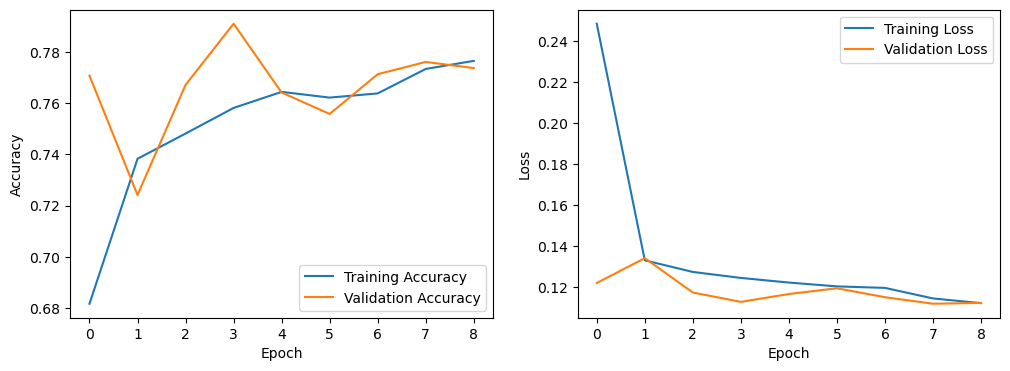

In [88]:

# Plot training history
plt.figure(figsize=(12, 4))

# Plot accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

### Confusion Matrix

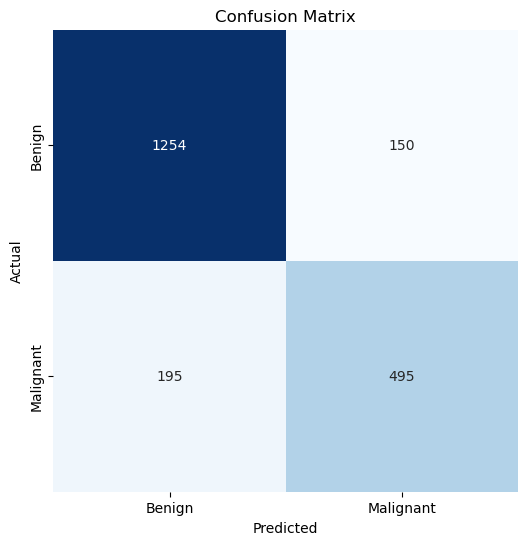

In [87]:
cm = confusion_matrix(y_true, np.round(y_pred))
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [92]:
# Save the model
# model.save('skin_analyzer_model.keras')
model.save('skin_analyzer_model.h5')


print("saved ")

saved 


In [4]:

# Load the saved model
model = tf.keras.models.load_model('skin_analyzer_model.h5')

# Convert the model to TFLite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the TFLite model
with open('skin_analyzer_model.tflite', 'wb') as f:
    f.write(tflite_model)

print("Model saved.")

INFO:tensorflow:Assets written to: C:\Users\BABARR~1\AppData\Local\Temp\tmpn6ydls4f\assets


INFO:tensorflow:Assets written to: C:\Users\BABARR~1\AppData\Local\Temp\tmpn6ydls4f\assets


Saved artifact at 'C:\Users\BABARR~1\AppData\Local\Temp\tmpn6ydls4f'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_5')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  2655053978832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053979600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053980560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053979024: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053980176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053979792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053979216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053979984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053981136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2655053981904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  2

In [7]:
# Load the TFLite model
interpreter = tf.lite.Interpreter(model_path='skin_analyzer_model.tflite')
interpreter.allocate_tensors()

# Get input and output tensors
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

# Function to preprocess the image
def preprocess_image(image_path):
    img = Image.open(image_path).resize((224, 224))  # Resize to model's input size (adjust if different)
    img = np.array(img).astype('float32') / 255.0  # Normalize to [0, 1]
    img = np.expand_dims(img, axis=0)  # Add batch dimension
    return img

# Function to make a prediction
def predict(image_path):
    input_data = preprocess_image(image_path)
    interpreter.set_tensor(input_details[0]['index'], input_data)
    interpreter.invoke()
    output_data = interpreter.get_tensor(output_details[0]['index'])
    return output_data

# Test on a random image
image_path = r'sample_image'  # Replace with your image path
prediction = predict(image_path)

# Assuming binary classification (e.g., malignant vs. benign)
print(f"Prediction: {'malignant' if prediction[0][0] > 0.5 else 'benign'}")
print(f"Raw output: {prediction}")

Prediction: benign
Raw output: [[0.03624335]]
